🚀 월별 재구매율 트렌드 분석 시작!
📅 분석 기간: 2016-09 ~ 2018-08
📊 총 23개월 데이터

📊 시각화 생성 중...


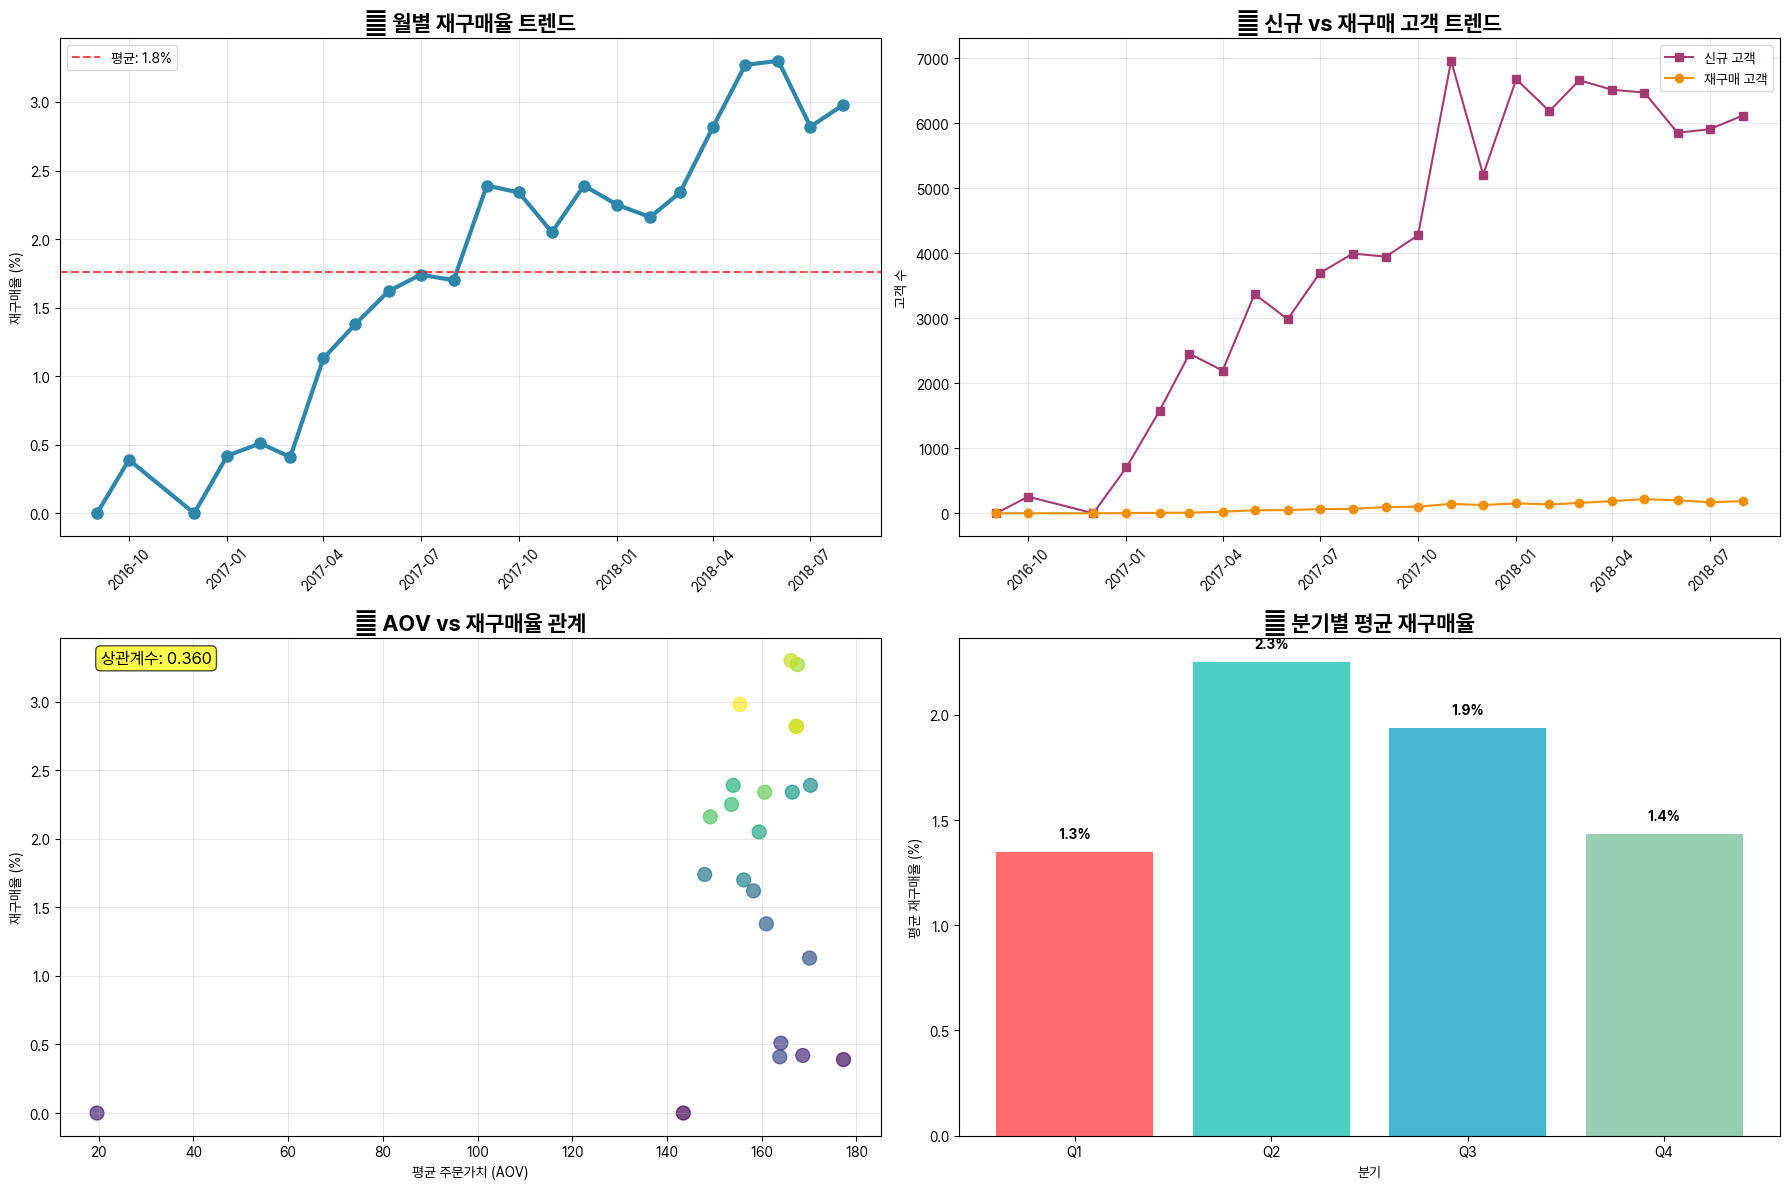


📊 월별 재구매율 트렌드 분석 결과

📈 재구매율 기본 통계:
   평균: 1.76%
   중앙값: 2.05%
   최고: 3.30% (2018-06)
   최저: 0.00% (2016-09)
   표준편차: 1.05%

📊 트렌드 분석:
   전반기 평균: 0.85%
   후반기 평균: 2.59%
   전체 트렌드: 상승 (1.75%p 차이)

🎯 안정성 분석:
   변동계수: 59.6%
   안정성 평가: 변동성 있음

💰 AOV 연관성:
   상관계수: 0.360
   관계 해석: 약한 양의 상관

📅 계절성 분석:
   최고 분기: Q2 (2.25%)
   최저 분기: Q1 (1.35%)
   계절성 강도: 0.91%p 차이

💡 비즈니스 인사이트:
   ⚠️  재구매율이 5% 미만으로 개선이 필요합니다
   📋 권장사항: 첫 구매 경험 개선, 재구매 인센티브 강화
   ⚠️  재구매율 변동성이 높아 일관성 있는 전략이 필요합니다

✅ 분석 완료!
💡 핵심 결과: 평균 재구매율 1.8%, 상승 트렌드


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 설정
plt.rcParams['font.family'] = 'pretendard'
plt.rcParams['axes.unicode_minus'] = False

# =============================================================================
# 📊 월별 재구매율 트렌드 분석
# =============================================================================

def load_monthly_kpi_data():
    """dm_kpi_overview.csv에서 월별 KPI 데이터 로드"""
    
    # CSV 파일에서 데이터 로드
    df_kpi = pd.read_csv('../data/dm_kpi_overview.csv')
    
    # 데이터 전처리
    df_kpi['month_key'] = pd.to_datetime(df_kpi['month_key'])
    df_kpi = df_kpi.sort_values('month_key')
    
    print(f"📅 분석 기간: {df_kpi['month_key'].min().strftime('%Y-%m')} ~ {df_kpi['month_key'].max().strftime('%Y-%m')}")
    print(f"📊 총 {len(df_kpi)}개월 데이터")
    
    return df_kpi

def create_repeat_rate_trend(df_kpi):
    """재구매율 트렌드 라인 차트 생성"""
    
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    
    # 1. 메인 트렌드: 재구매율
    axes[0,0].plot(df_kpi['month_key'], df_kpi['repeat_rate_pct'], 
                   marker='o', linewidth=3, markersize=8, color='#2E86AB')
    axes[0,0].set_title('📈 월별 재구매율 트렌드', fontsize=16, fontweight='bold')
    axes[0,0].set_ylabel('재구매율 (%)')
    axes[0,0].grid(True, alpha=0.3)
    axes[0,0].tick_params(axis='x', rotation=45)
    
    # 평균선 추가
    avg_repeat_rate = df_kpi['repeat_rate_pct'].mean()
    axes[0,0].axhline(y=avg_repeat_rate, color='red', linestyle='--', alpha=0.7, 
                      label=f'평균: {avg_repeat_rate:.1f}%')
    axes[0,0].legend()
    
    # 2. 신규 vs 재구매 고객 비율
    axes[0,1].plot(df_kpi['month_key'], df_kpi['new_customers'], 
                   marker='s', label='신규 고객', color='#A23B72')
    axes[0,1].plot(df_kpi['month_key'], df_kpi['repeat_customers'], 
                   marker='o', label='재구매 고객', color='#F18F01')
    axes[0,1].set_title('👥 신규 vs 재구매 고객 트렌드', fontsize=16, fontweight='bold')
    axes[0,1].set_ylabel('고객 수')
    axes[0,1].legend()
    axes[0,1].grid(True, alpha=0.3)
    axes[0,1].tick_params(axis='x', rotation=45)
    
    # 3. AOV vs 재구매율 관계
    scatter = axes[1,0].scatter(df_kpi['aov'], df_kpi['repeat_rate_pct'], 
                               c=df_kpi.index, cmap='viridis', s=100, alpha=0.7)
    axes[1,0].set_xlabel('평균 주문가치 (AOV)')
    axes[1,0].set_ylabel('재구매율 (%)')
    axes[1,0].set_title('💰 AOV vs 재구매율 관계', fontsize=16, fontweight='bold')
    axes[1,0].grid(True, alpha=0.3)
    
    # 상관계수 계산
    correlation = np.corrcoef(df_kpi['aov'], df_kpi['repeat_rate_pct'])[0,1]
    axes[1,0].text(0.05, 0.95, f'상관계수: {correlation:.3f}', 
                   transform=axes[1,0].transAxes, fontsize=12, 
                   bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))
    
    # 4. 계절성 분석 (분기별)
    df_kpi['quarter'] = df_kpi['month_key'].dt.quarter
    quarterly_repeat = df_kpi.groupby('quarter')['repeat_rate_pct'].mean()
    
    bars = axes[1,1].bar(quarterly_repeat.index, quarterly_repeat.values, 
                        color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4'])
    axes[1,1].set_title('📅 분기별 평균 재구매율', fontsize=16, fontweight='bold')
    axes[1,1].set_xlabel('분기')
    axes[1,1].set_ylabel('평균 재구매율 (%)')
    axes[1,1].set_xticks(range(1, 5))
    axes[1,1].set_xticklabels(['Q1', 'Q2', 'Q3', 'Q4'])
    
    # 막대 위에 값 표시
    for bar, value in zip(bars, quarterly_repeat.values):
        axes[1,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
                      f'{value:.1f}%', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    return fig

def analyze_repeat_rate_insights(df_kpi):
    """재구매율 인사이트 분석"""
    
    print("\n" + "="*60)
    print("📊 월별 재구매율 트렌드 분석 결과")
    print("="*60)
    
    # 기본 통계
    repeat_stats = df_kpi['repeat_rate_pct'].describe()
    print(f"\n📈 재구매율 기본 통계:")
    print(f"   평균: {repeat_stats['mean']:.2f}%")
    print(f"   중앙값: {repeat_stats['50%']:.2f}%")
    print(f"   최고: {repeat_stats['max']:.2f}% ({df_kpi.loc[df_kpi['repeat_rate_pct'].idxmax(), 'month_name']})")
    print(f"   최저: {repeat_stats['min']:.2f}% ({df_kpi.loc[df_kpi['repeat_rate_pct'].idxmin(), 'month_name']})")
    print(f"   표준편차: {repeat_stats['std']:.2f}%")
    
    # 트렌드 분석
    first_half = df_kpi.iloc[:len(df_kpi)//2]['repeat_rate_pct'].mean()
    second_half = df_kpi.iloc[len(df_kpi)//2:]['repeat_rate_pct'].mean()
    trend = "상승" if second_half > first_half else "하락" if second_half < first_half else "안정"
    
    print(f"\n📊 트렌드 분석:")
    print(f"   전반기 평균: {first_half:.2f}%")
    print(f"   후반기 평균: {second_half:.2f}%")
    print(f"   전체 트렌드: {trend} ({abs(second_half - first_half):.2f}%p 차이)")
    
    # 안정성 분석
    cv = (repeat_stats['std'] / repeat_stats['mean']) * 100
    stability = "매우 안정" if cv < 5 else "안정" if cv < 10 else "변동성 있음"
    
    print(f"\n🎯 안정성 분석:")
    print(f"   변동계수: {cv:.1f}%")
    print(f"   안정성 평가: {stability}")
    
    # AOV와의 관계
    aov_corr = np.corrcoef(df_kpi['aov'], df_kpi['repeat_rate_pct'])[0,1]
    aov_relationship = "강한 양의 상관" if aov_corr > 0.7 else "약한 양의 상관" if aov_corr > 0.3 else "약한 음의 상관" if aov_corr < -0.3 else "상관관계 없음"
    
    print(f"\n💰 AOV 연관성:")
    print(f"   상관계수: {aov_corr:.3f}")
    print(f"   관계 해석: {aov_relationship}")
    
    # 계절성 분석
    quarterly_data = df_kpi.groupby('quarter')['repeat_rate_pct'].agg(['mean', 'std'])
    best_quarter = quarterly_data['mean'].idxmax()
    worst_quarter = quarterly_data['mean'].idxmin()
    
    print(f"\n📅 계절성 분석:")
    print(f"   최고 분기: Q{best_quarter} ({quarterly_data.loc[best_quarter, 'mean']:.2f}%)")
    print(f"   최저 분기: Q{worst_quarter} ({quarterly_data.loc[worst_quarter, 'mean']:.2f}%)")
    print(f"   계절성 강도: {quarterly_data['mean'].max() - quarterly_data['mean'].min():.2f}%p 차이")
    
    # 비즈니스 인사이트
    print(f"\n💡 비즈니스 인사이트:")
    if repeat_stats['mean'] < 5:
        print("   ⚠️  재구매율이 5% 미만으로 개선이 필요합니다")
        print("   📋 권장사항: 첫 구매 경험 개선, 재구매 인센티브 강화")
    elif repeat_stats['mean'] < 10:
        print("   📊 재구매율이 보통 수준입니다")
        print("   📋 권장사항: 고객 세그먼트별 맞춤 전략 수립")
    else:
        print("   ✅ 재구매율이 우수한 수준입니다")
        print("   📋 권장사항: 현재 전략 유지 및 VIP 고객 관리 강화")
    
    if cv > 10:
        print("   ⚠️  재구매율 변동성이 높아 일관성 있는 전략이 필요합니다")
    
    return {
        'avg_repeat_rate': repeat_stats['mean'],
        'trend': trend,
        'stability': stability,
        'best_month': df_kpi.loc[df_kpi['repeat_rate_pct'].idxmax(), 'month_name'],
        'best_quarter': f"Q{best_quarter}"
    }

def main():
    """메인 실행 함수"""
    
    print("🚀 월별 재구매율 트렌드 분석 시작!")
    print("="*50)
    
    try:
        # 1. 데이터 로드
        df_kpi = load_monthly_kpi_data()
        
        # 2. 시각화 생성
        print("\n📊 시각화 생성 중...")
        fig = create_repeat_rate_trend(df_kpi)
        
        # 3. 인사이트 분석
        insights = analyze_repeat_rate_insights(df_kpi)
        
        print(f"\n✅ 분석 완료!")
        print(f"💡 핵심 결과: 평균 재구매율 {insights['avg_repeat_rate']:.1f}%, {insights['trend']} 트렌드")
        
        return df_kpi, insights
        
    except FileNotFoundError:
        print("❌ 오류: dm_kpi_overview.csv 파일을 찾을 수 없습니다.")
        print("💡 파일 경로를 확인해주세요.")
        return None, None
    
    except Exception as e:
        print(f"❌ 오류 발생: {str(e)}")
        return None, None

# 실행
if __name__ == "__main__":
    df_data, analysis_results = main()